# 01 - Análisis Exploratorio de Datos (EDA)

**Proyecto 2: VectorIA** - Colegio Universitario de Cartago (CUC)

**Integrantes:** Mariana Méndez Pérez · Luis Diego Montero Vargas · Nadin Rojas López · Claret Rodríguez Jiménez

## Objetivo
Conocer los datos reales de dengue y clima de Costa Rica antes de entrenar los modelos. Queremos entender cómo se comportan los casos en el tiempo, qué relación tienen con el clima (sobre todo con el **rezago**: el clima influye semanas después) y qué problemas de calidad tienen los datos.

## Datos utilizados
| Archivo | Uso | Tipo |
|---|---|---|
| `vectoria_dengue_nacional_real.csv` | Módulo 2 (LSTM): 574 semanas de casos y clima (2014-2024) | Real |
| `vectoria_acciones.csv` | Módulo 3 (ANN): recomendaciones por semana y escenario | Mixto |
| `vectoria_casos_cantonal_anual_real.csv` | Mapa de calor del dashboard (2013-2018) | Real |

**Fuentes:** casos de OPS/PAHO vía OpenDengue; clima de NASA POWER.

## Organización del código
La carga y transformación de los datos no se escribe en este notebook, sino en las clases del archivo `src/data_prep.py`:
- **`PreparadorDatos`**: carga los CSV, crea logaritmos, rezagos y el baseline estacional, divide en train/test y guarda los datos procesados.
- **`AnalizadorSerie`**: calcula correlaciones con rezago, detecta subregistro y calcula errores (RMSE, MAE).

Así, los notebooks del LSTM y de la ANN y la app reutilizan exactamente el mismo código.

## Contenido del notebook
1. Carga y revisión general de los datos
2. Estadísticas descriptivas
3. Casos de dengue a lo largo del tiempo
4. Subregistro de fin de año
5. Valores atípicos
6. Estacionalidad
7. Relación entre las variables del clima
8. Correlación y rezago entre clima y casos
9. Baseline estacional y división train/test
10. Dataset de acciones (Módulo 3 - ANN)
11. Dataset cantonal (mapa de calor)
12. Guardar los datos procesados
13. Conclusiones

## 1. Carga y revisión general de los datos
Usamos la clase `PreparadorDatos`. El método `cargar_nacional()` lee el CSV, convierte la fecha a formato fecha, elimina las columnas que tienen un solo valor y agrega el mes del año.

In [4]:
import sys
sys.path.append("..")  # para que el notebook encuentre la carpeta src/

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from src.data_prep import PreparadorDatos, AnalizadorSerie

preparador = PreparadorDatos()
df = preparador.cargar_nacional()
df.head()

,fecha_inicio_semana,anio,semana_epi,casos_dengue,tasa_100k,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct,mes
0,2013-12-29,2014,1,239,4.62,11.0,27.2,19.9,84.9,12
1,2014-01-05,2014,2,257,4.97,8.9,27.0,19.7,83.8,1
2,2014-01-12,2014,3,184,3.56,4.5,27.1,19.5,81.7,1
3,2014-01-19,2014,4,156,3.02,7.7,27.1,19.5,80.0,1
4,2014-01-26,2014,5,189,3.66,4.7,27.2,18.7,78.0,1


In [5]:
# Tamaño, tipos de datos y valores faltantes
print("Filas y columnas:", df.shape)
print("Valores faltantes:", df.isna().sum().sum())
df.info()

Filas y columnas: (574, 10)
Valores faltantes: 0
<class 'pandas.DataFrame'>
RangeIndex: 574 entries, 0 to 573
Data columns (total 10 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   fecha_inicio_semana  574 non-null    datetime64[us]
 1   anio                 574 non-null    int64         
 2   semana_epi           574 non-null    int64         
 3   casos_dengue         574 non-null    int64         
 4   tasa_100k            574 non-null    float64       
 5   lluvia_mm            574 non-null    float64       
 6   temp_max_c           574 non-null    float64       
 7   temp_min_c           574 non-null    float64       
 8   humedad_rel_pct      574 non-null    float64       
 9   mes                  574 non-null    int32         
dtypes: datetime64[us](1), float64(5), int32(1), int64(3)
memory usage: 42.7 KB


In [6]:
# ¿Las semanas son consecutivas? (la diferencia entre fechas debe ser siempre de 7 días)
print(df["fecha_inicio_semana"].diff().value_counts())
print("Desde", df["fecha_inicio_semana"].min().date(), "hasta", df["fecha_inicio_semana"].max().date())

fecha_inicio_semana
7 days    573
Name: count, dtype: int64
Desde 2013-12-29 hasta 2024-12-22


### Interpretación
- Son **574 semanas** sin valores faltantes, desde el 29 de diciembre de 2013 (semana 1 de 2014) hasta diciembre de 2024.
- Todas las semanas están separadas por 7 días exactos, así que **no hay semanas perdidas** en la serie. Esto es importante para el LSTM, que necesita una serie continua.
- En el CSV original, `provincia`, `region_climatica` y `poblacion` tienen **un solo valor** en todas las filas ("Costa Rica", "Nacional" y 5,170,000), porque la serie es nacional. No aportan información, por eso `cargar_nacional()` las elimina.

## 2. Estadísticas descriptivas

In [7]:
df[["casos_dengue", "lluvia_mm", "temp_max_c", "temp_min_c", "humedad_rel_pct"]].describe().round(2)

,casos_dengue,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
count,574.00,574.00,574.00,574.00,574.00
mean,268.59,51.97,27.84,21.12,83.72
std,304.17,57.64,1.71,0.91,7.66
min,12.00,0.00,24.40,18.40,61.80
25%,71.00,13.58,26.70,20.50,79.43
50%,156.00,38.50,27.40,21.20,86.70
75%,328.00,75.40,28.70,21.80,89.30
max,1749.00,625.20,33.00,23.20,94.90


### Interpretación
- Los casos de dengue tienen un promedio (268) mucho mayor que la mediana (156). Esto indica que la mayoría de las semanas tienen pocos casos y que hay unas pocas semanas de brote con muchísimos casos (máximo 1,749).
- La lluvia tiene el mismo comportamiento: promedio de 52 mm, mediana de 38.5 mm y un máximo de 625.2 mm, que es un valor extremo.
- Las temperaturas casi no cambian de una semana a otra (desviación de 1.7 °C en la máxima y 0.9 °C en la mínima).
- Las variables tienen escalas muy distintas, así que hay que escalarlas antes de entrenar el modelo.
- Como los casos y la lluvia están tan sesgados, conviene trabajarlos en **logaritmo** (se usa en las secciones 8 y 9).

## 3. Casos de dengue a lo largo del tiempo
Graficamos la serie semanal de casos para ver la tendencia y los brotes.

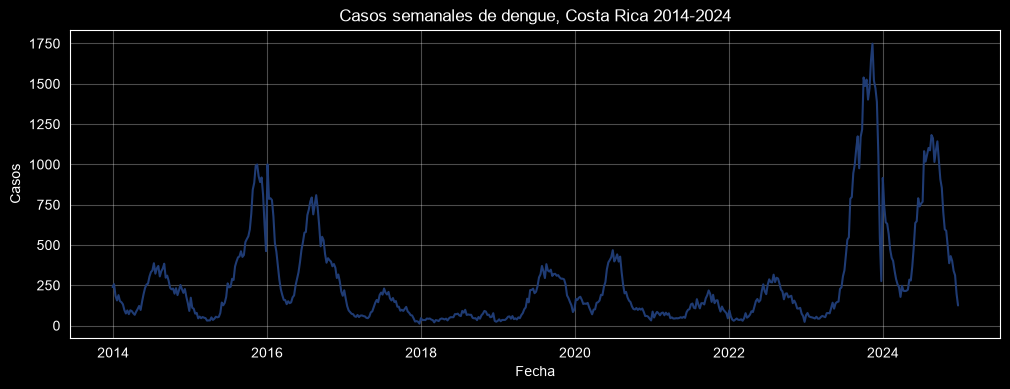

In [8]:
plt.figure(figsize=(12, 4))
plt.plot(df["fecha_inicio_semana"], df["casos_dengue"], color="#1f3b73")
plt.title("Casos semanales de dengue, Costa Rica 2014-2024")
plt.xlabel("Fecha")
plt.ylabel("Casos")
plt.grid(alpha=0.3)
plt.show()

### Interpretación
- Los brotes más grandes son los de 2023 (máximo de 1,749 casos en una semana) y 2024 (cerca de 1,200). También hay picos importantes en 2015 y 2016, de casi 1,000 casos.
- Entre 2017 y 2019 y entre 2021 y 2022 los casos se mantienen bajos.
- La serie no sigue una tendencia fija: sube y baja en ciclos, con años de brote y años tranquilos.
- Al final de 2023 hay una caída muy brusca y corta de los casos. En la sección 4 comprobamos que se debe a un **problema de registro** que se repite todos los años.

### Comparación entre años
Superponemos los años usando la semana epidemiológica (1 a 53) en el eje horizontal. Los años de brote se resaltan con color.

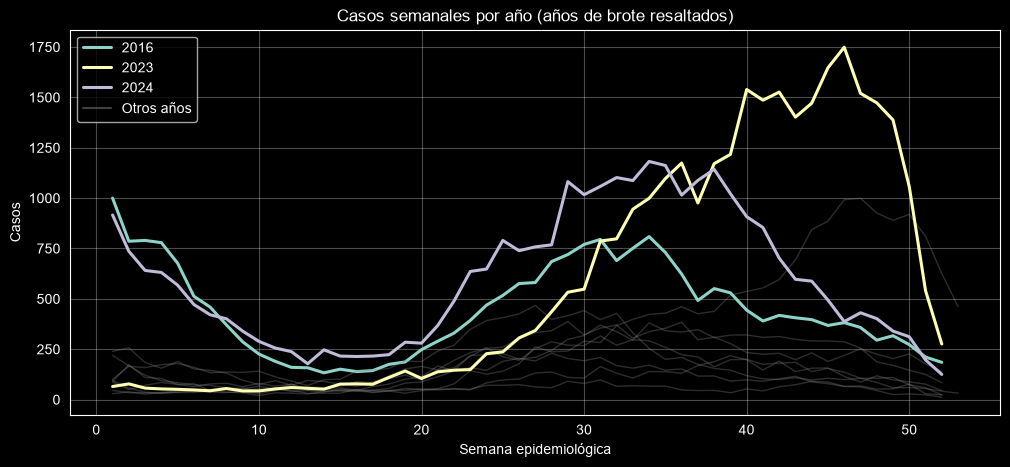

,total,maximo_semanal
anio,,
2014,11049,387
2015,17485,999
2016,23319,1000
2017,5561,230
2018,2735,98
2019,9400,381
2020,10056,468
2021,5174,218
2022,7485,316


In [9]:
anios_brote = [2016, 2023, 2024]

plt.figure(figsize=(12, 5))
for anio, datos in df.groupby("anio"):
    if anio in anios_brote:
        plt.plot(datos["semana_epi"], datos["casos_dengue"], linewidth=2.2, label=str(anio))
    else:
        plt.plot(datos["semana_epi"], datos["casos_dengue"], color="grey", alpha=0.35, linewidth=1)

plt.plot([], [], color="grey", alpha=0.5, label="Otros años")
plt.title("Casos semanales por año (años de brote resaltados)")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Casos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

df.groupby("anio")["casos_dengue"].agg(total="sum", maximo_semanal="max")

### Interpretación
- Casi todos los años siguen la **misma forma**: pocos casos entre las semanas 5 y 18 (febrero a abril) y un aumento a partir de la semana 20 aproximadamente (mayo-junio).
- Lo que cambia entre años es la **altura** de la curva. En 2023 y 2024 hubo más de 30,000 casos al año, unas **seis veces más** que en años tranquilos como 2017 o 2021 (unos 5,000).
- **2016 y 2024** empiezan el año con muchos casos (cerca de 1,000 por semana), porque arrastran el brote de finales del año anterior (2015 y 2023).
- El pico no ocurre siempre en la misma semana: en 2024 llegó entre las semanas 29 y 38, mientras que en 2023 fue entre las semanas 40 y 46.
- Esto indica que el modelo no solo debe aprender la época del año, sino también **cuánto vienen subiendo los casos** en las semanas anteriores.

## 4. Subregistro de fin de año
En la serie se ve una caída brusca a finales de 2023. Revisamos si es un fenómeno real o un problema de registro, y si se repite en otros años.

Para cada semana calculamos la **razón** entre sus casos y el promedio de las semanas vecinas (2 antes y 2 después), con el método `efecto_semana_epi()` de la clase `AnalizadorSerie`. Una razón de 1 es normal; menor a 1 significa menos casos de lo esperado.

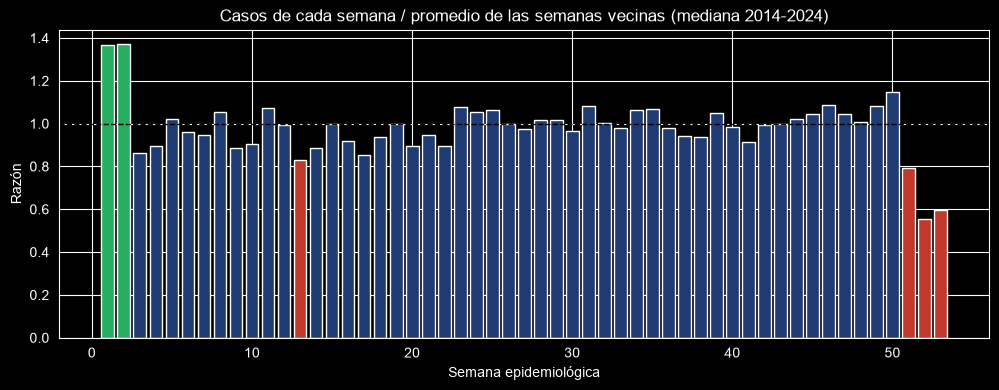

,razon
semana_epi,
48,1.01
49,1.08
50,1.15
51,0.79
52,0.56
53,0.59
1,1.37
2,1.37
3,0.86


In [10]:
analizador = AnalizadorSerie(df)
razon = analizador.efecto_semana_epi()

colores = ["#c0392b" if r < 0.85 else "#27ae60" if r > 1.2 else "#1f3b73" for r in razon]
plt.figure(figsize=(12, 4))
plt.bar(razon.index, razon.values, color=colores)
plt.axhline(1, color="black", linestyle="--", linewidth=1)
plt.title("Casos de cada semana / promedio de las semanas vecinas (mediana 2014-2024)")
plt.xlabel("Semana epidemiológica")
plt.ylabel("Razón")
plt.show()

razon.loc[[48, 49, 50, 51, 52, 53, 1, 2, 3]].round(2).to_frame("razon")

In [11]:
# Detalle del caso de 2023
df[(df["fecha_inicio_semana"] >= "2023-11-26") & (df["fecha_inicio_semana"] <= "2024-01-21")][
    ["fecha_inicio_semana", "semana_epi", "casos_dengue"]
]

,fecha_inicio_semana,semana_epi,casos_dengue
517,2023-11-26,48,1473
518,2023-12-03,49,1388
519,2023-12-10,50,1057
520,2023-12-17,51,541
521,2023-12-24,52,276
522,2023-12-31,1,916
523,2024-01-07,2,736
524,2024-01-14,3,641
525,2024-01-21,4,631


### Interpretación
- La caída de 2023 **no es un caso aislado**: en todos los años, las semanas 51, 52 y 53 reportan entre un 20 % y un 45 % menos casos de lo esperado.
- Justo después, en las semanas 1 y 2, se reportan alrededor de un **37 % más** de casos de lo esperado.
- El patrón coincide con las **vacaciones de fin de año**: en esas semanas se registran menos casos y se acumulan para las primeras semanas de enero. En 2023, por ejemplo, la semana del 24 de diciembre tuvo 276 casos y la siguiente subió a 916.
- La semana 13 también aparece baja (0.83). Coincide con la época de **Semana Santa**, otro periodo de feriados. El efecto es menor porque Semana Santa cambia de semana cada año.
- **Conclusión:** es un problema de **registro**, no un cambio real en la enfermedad.
- **Decisión:** no modificamos los datos, porque son los oficiales. Pero lo tomamos en cuenta al evaluar el LSTM: es esperable que el modelo falle más en esas semanas, y lo explicaremos en el informe técnico.

## 5. Valores atípicos
Revisamos si hay valores muy fuera de lo normal en los casos y en la lluvia, y en qué fechas ocurrieron.

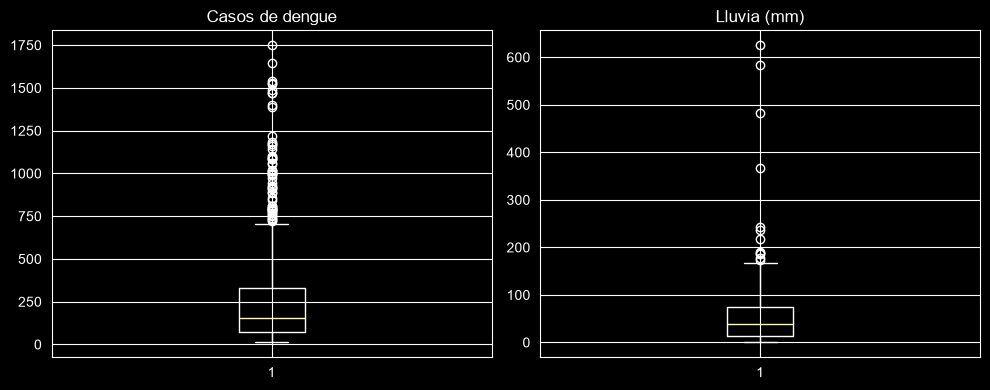

,fecha_inicio_semana,lluvia_mm,casos_dengue
543,2024-05-26,625.2,489
357,2020-11-01,583.6,106
567,2024-11-10,483.4,387
196,2017-10-01,368.0,98
544,2024-06-02,242.4,636


In [12]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 4))

ejes[0].boxplot(df["casos_dengue"])
ejes[0].set_title("Casos de dengue")

ejes[1].boxplot(df["lluvia_mm"])
ejes[1].set_title("Lluvia (mm)")

plt.tight_layout()
plt.show()

# Las 5 semanas con más lluvia
df.nlargest(5, "lluvia_mm")[["fecha_inicio_semana", "lluvia_mm", "casos_dengue"]]

### Interpretación
- En los casos de dengue, los valores atípicos son las semanas de brote (más de unos 700 casos). Son datos reales de los brotes de 2016, 2023 y 2024, por eso no se eliminan.
- En la lluvia también hay valores atípicos. Las semanas más extremas fueron el 2024-05-26 (625.2 mm), el 2020-11-01 (583.6 mm), el 2024-11-10 (483.4 mm) y el 2017-10-01 (368 mm).
- Tres de esas semanas coinciden con eventos conocidos que indica el LEEME: el huracán Nate (oct. 2017), Eta (nov. 2020) y la tormenta Sara (nov. 2024).
- Los casos de esas mismas semanas no fueron especialmente altos. Si la lluvia influye, el efecto debería verse semanas después, y eso lo revisamos con los rezagos.
- **Decisión:** dejamos todos los valores atípicos porque son eventos reales y el modelo debe aprender de ellos. Para reducir su peso usamos el logaritmo de la lluvia (sección 8).

## 6. Estacionalidad
Revisamos si los casos de dengue y la lluvia cambian según el mes del año.

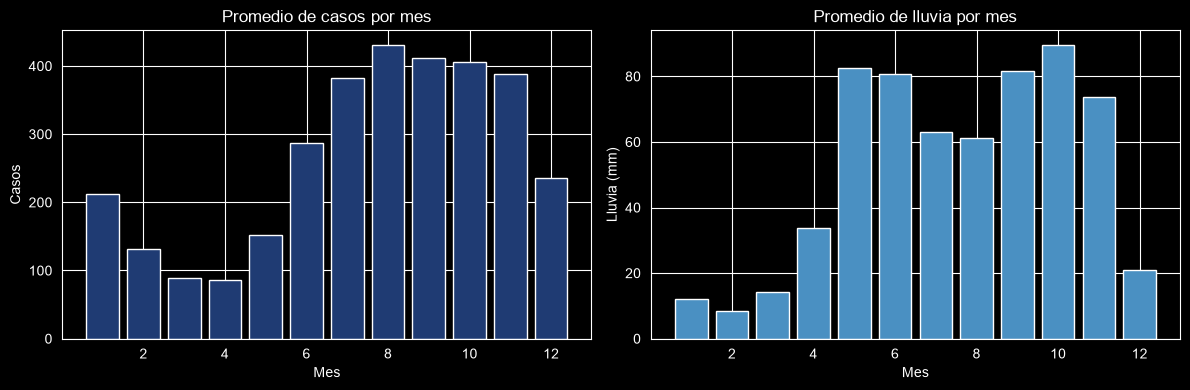

In [13]:
promedio_mensual = df.groupby("mes")[["casos_dengue", "lluvia_mm"]].mean()

fig, ejes = plt.subplots(1, 2, figsize=(12, 4))

ejes[0].bar(promedio_mensual.index, promedio_mensual["casos_dengue"], color="#1f3b73")
ejes[0].set_title("Promedio de casos por mes")
ejes[0].set_xlabel("Mes")
ejes[0].set_ylabel("Casos")

ejes[1].bar(promedio_mensual.index, promedio_mensual["lluvia_mm"], color="#4a90c2")
ejes[1].set_title("Promedio de lluvia por mes")
ejes[1].set_xlabel("Mes")
ejes[1].set_ylabel("Lluvia (mm)")

plt.tight_layout()
plt.show()

### Interpretación
- Los casos de dengue tienen estacionalidad: son más bajos en marzo y abril (unos 90 casos promedio) y más altos en agosto (unos 430), manteniéndose altos hasta noviembre.
- La lluvia es muy baja de enero a marzo y sube fuerte desde mayo. El máximo promedio es en octubre.
- La lluvia sube en mayo y los casos suben después, entre junio y agosto. Esto sugiere que la lluvia no afecta los casos de inmediato, sino semanas más tarde. Lo comprobamos con los rezagos en la sección 8.
- Estos promedios incluyen los años de brote (2016, 2023 y 2024), que pesan mucho. Sirven para ver el patrón general, pero no prueban por sí solos que la lluvia cause los casos.

## 7. Relación entre las variables del clima
Antes de ver la relación con los casos, revisamos si las variables del clima se parecen entre sí. Si dos variables están muy correlacionadas, aportan casi la misma información al modelo.

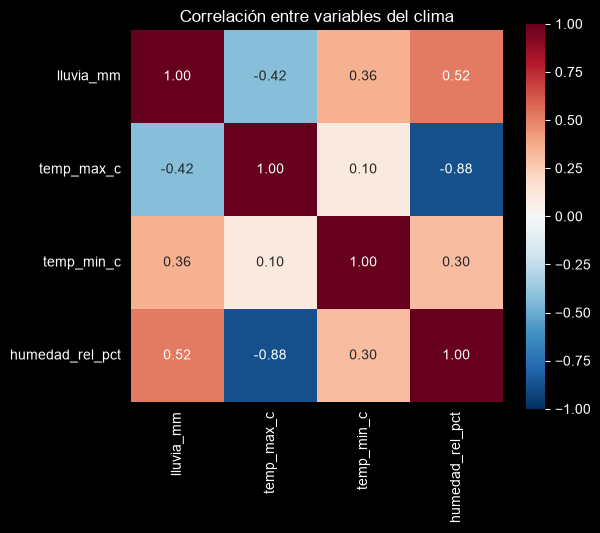

In [14]:
correlacion_clima = df[preparador.VARIABLES_CLIMA].corr()

plt.figure(figsize=(6, 5))
sns.heatmap(correlacion_clima, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True)
plt.title("Correlación entre variables del clima")
plt.show()

### Interpretación
- La **temperatura máxima y la humedad** tienen una correlación de **-0.88**: cuando hace más calor de día, el aire está más seco. Prácticamente miden lo mismo con el signo cambiado.
- La lluvia se relaciona de forma moderada con la humedad (0.52) y con la temperatura máxima (-0.42): las semanas lluviosas son más húmedas y menos calurosas.
- La **temperatura mínima** casi no se relaciona con la máxima (0.10), así que aporta información distinta.
- Esto explica por qué la temperatura máxima es difícil de interpretar en la sección 8: su relación con los casos es en buena parte la de la humedad, con el signo al revés.
- **Decisión:** para el modelo es suficiente usar una de las dos (humedad o temperatura máxima). Si se usan ambas, no aportan mucha información extra.

## 8. Correlación y rezago entre clima y casos
Calculamos la correlación entre los casos de dengue (en logaritmo) y cada variable del clima de semanas anteriores (rezagos de 0 a 12 semanas), con el método `correlacion_rezagos()`. Así vemos con cuántas semanas de rezago la relación es más fuerte.

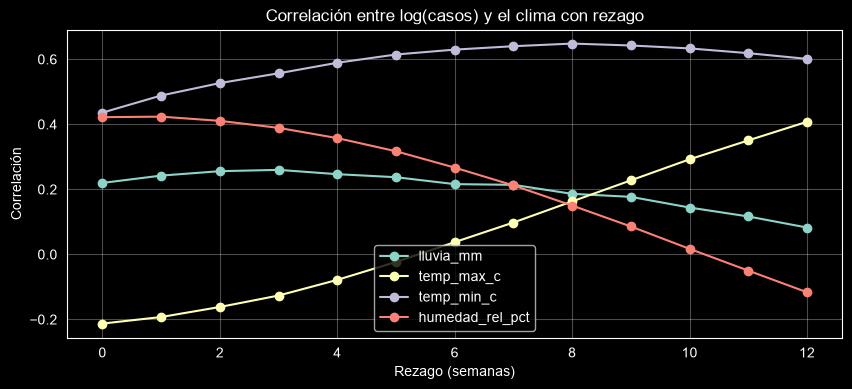

,lluvia_mm,temp_max_c,temp_min_c,humedad_rel_pct
rezago_semanas,,,,
0,0.22,-0.21,0.44,0.42
1,0.24,-0.19,0.49,0.42
2,0.26,-0.16,0.53,0.41
3,0.26,-0.13,0.56,0.39
4,0.25,-0.08,0.59,0.36
5,0.24,-0.02,0.61,0.32
6,0.22,0.04,0.63,0.27
7,0.21,0.10,0.64,0.21
8,0.19,0.16,0.65,0.15


In [15]:
# Agregamos log(casos) y log(1 + lluvia) con la clase
df = preparador.agregar_logaritmos(df)
analizador = AnalizadorSerie(df)

correlaciones = analizador.correlacion_rezagos("log_casos", preparador.VARIABLES_CLIMA, max_rezago=12)

correlaciones.plot(figsize=(10, 4), marker="o")
plt.title("Correlación entre log(casos) y el clima con rezago")
plt.xlabel("Rezago (semanas)")
plt.ylabel("Correlación")
plt.grid(alpha=0.3)
plt.show()

correlaciones.round(2)

### Interpretación
- La **temperatura mínima** es la variable que más se relaciona con los casos. La correlación sube con el rezago: 0.44 sin rezago y 0.65 con 8 semanas. Entre 6 y 9 semanas casi no cambia, así que la mejor zona de rezago está entre 6 y 9 semanas.
- La lluvia en milímetros tiene una relación débil: su máximo es 0.26, con 2 a 3 semanas de rezago.
- La humedad se relaciona más con los casos sin rezago (0.42) y pierde fuerza al aumentar el rezago.
- La temperatura máxima cambia de signo según el rezago. Como vimos en la sección 7, esto se debe a que está muy ligada a la humedad.

### ¿Por qué nuestros valores de lluvia no coinciden con el LEEME?
El LEEME del profe reporta r ≈ 0.34 para la lluvia, pero nosotros obtuvimos 0.26. Probamos dos formas de medir la lluvia que reducen el efecto de las tormentas extremas:
- **log(1 + lluvia):** comprime los valores extremos.
- **Lluvia acumulada de 4 semanas:** el mosquito necesita agua acumulada varios días, no la lluvia de una sola semana.

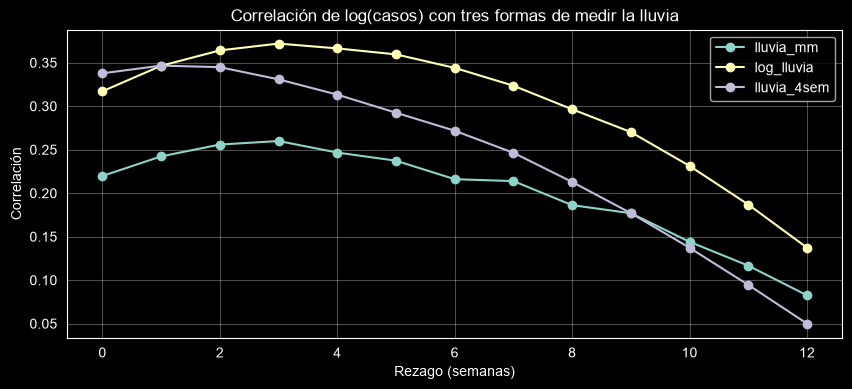

rezago_semanas,0,1,2,3,4,5,6,7,8,9,10,11,12
lluvia_mm,0.22,0.24,0.26,0.26,0.25,0.24,0.22,0.21,0.19,0.18,0.14,0.12,0.08
log_lluvia,0.32,0.35,0.36,0.37,0.37,0.36,0.34,0.32,0.30,0.27,0.23,0.19,0.14
lluvia_4sem,0.34,0.35,0.34,0.33,0.31,0.29,0.27,0.25,0.21,0.18,0.14,0.09,0.05


In [16]:
df["lluvia_4sem"] = df["lluvia_mm"].rolling(4).sum()
analizador = AnalizadorSerie(df)

comparacion_lluvia = analizador.correlacion_rezagos(
    "log_casos", ["lluvia_mm", "log_lluvia", "lluvia_4sem"], max_rezago=12
)

comparacion_lluvia.plot(figsize=(10, 4), marker="o")
plt.title("Correlación de log(casos) con tres formas de medir la lluvia")
plt.xlabel("Rezago (semanas)")
plt.ylabel("Correlación")
plt.grid(alpha=0.3)
plt.show()

comparacion_lluvia.round(2).T

### Interpretación
- Con **log(1 + lluvia)** la correlación sube de 0.26 a **0.37**, con 3 a 4 semanas de rezago.
- Con la **lluvia acumulada de 4 semanas** la correlación es **0.34** con 0 a 2 semanas de rezago, que es exactamente el valor del LEEME.
- **Conclusión:** la diferencia con el LEEME se debe a cómo se mide la lluvia. Las tormentas extremas (Nate, Eta, Sara) distorsionan la correlación cuando se usan los milímetros directamente.
- **Decisión:** usar `log_lluvia` en el modelo, en lugar de `lluvia_mm`.
- La temperatura y los casos siguen ciclos anuales, así que una correlación alta no prueba que una cause la otra.

### Autocorrelación de los casos
Revisamos cuánto se parecen los casos de una semana a los de semanas anteriores.

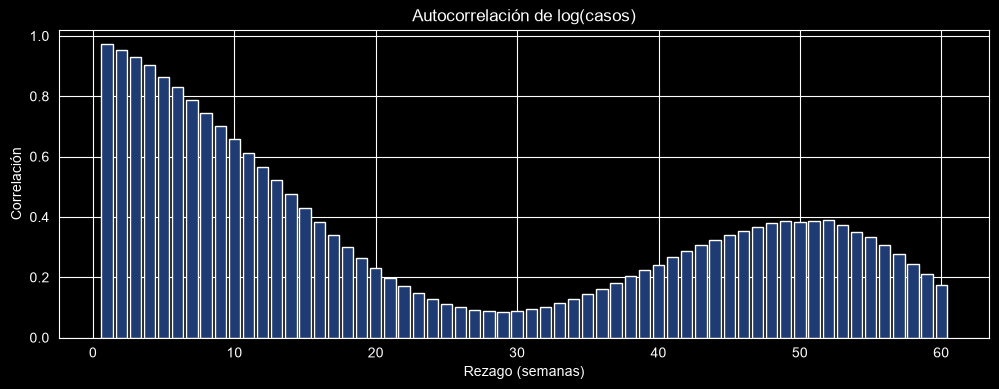

,autocorrelacion
1,0.97
2,0.95
4,0.90
8,0.74
26,0.10
52,0.39


In [17]:
autocorrelacion = pd.Series(
    [df["log_casos"].autocorr(k) for k in range(1, 61)], index=range(1, 61)
)

plt.figure(figsize=(12, 4))
plt.bar(autocorrelacion.index, autocorrelacion.values, color="#1f3b73")
plt.axhline(0, color="black", linewidth=0.8)
plt.title("Autocorrelación de log(casos)")
plt.xlabel("Rezago (semanas)")
plt.ylabel("Correlación")
plt.show()

autocorrelacion.loc[[1, 2, 4, 8, 26, 52]].round(2).to_frame("autocorrelacion")

### Interpretación
- Los casos de una semana se parecen muchísimo a los de la semana anterior (**0.97**) y siguen muy parecidos 4 semanas antes (**0.90**).
- Esta relación es **mucho más fuerte que cualquier variable del clima** (la mejor era 0.65).
- A las 26 semanas (medio año) la relación casi desaparece (0.10) y a las 52 semanas (un año) vuelve a subir (0.39), por la estacionalidad.
- **Decisión:** el LSTM debe recibir como entrada los **casos de las semanas anteriores**, además del clima. La ventana de 26 semanas del modelo cubre tanto esta memoria como los rezagos del clima.

## 9. Baseline estacional y división train/test
El proyecto pide comparar el LSTM contra un **baseline estacional**: predecir que cada semana tendrá los mismos casos que la misma semana del año anterior. Lo calculamos desde ahora para saber qué número debe superar el modelo.

Para el entrenamiento usamos una **división temporal**: 2014-2022 para entrenar y 2023-2024 para probar.

In [18]:
df = preparador.agregar_baseline_estacional(df)
train, test = preparador.dividir_temporal(df, fecha_corte="2023-01-01")

print("Semanas de entrenamiento:", len(train))
print("Semanas de prueba:", len(test))

errores_baseline = pd.DataFrame({
    "Toda la serie": AnalizadorSerie.errores(df["casos_dengue"], df["baseline_estacional"]),
    "Prueba (2023-2024)": AnalizadorSerie.errores(test["casos_dengue"], test["baseline_estacional"]),
}).T
errores_baseline

Semanas de entrenamiento: 470
Semanas de prueba: 104


,RMSE,MAE
Toda la serie,357.3,227.0
Prueba (2023-2024),630.7,447.5


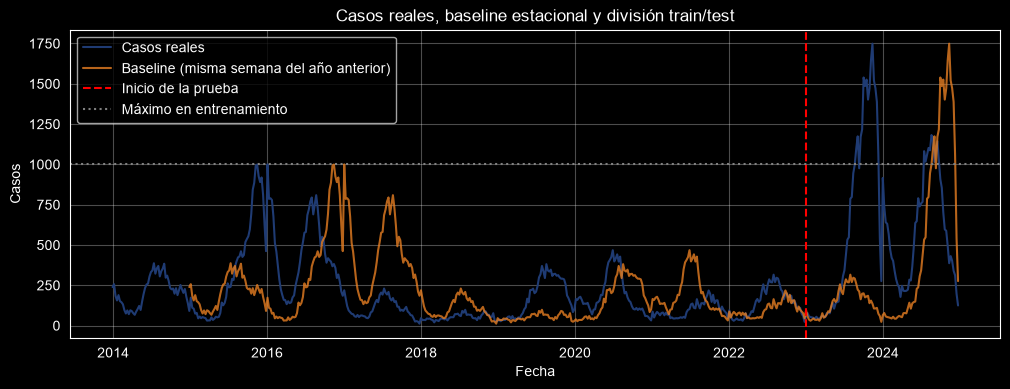

In [19]:
plt.figure(figsize=(12, 4))
plt.plot(df["fecha_inicio_semana"], df["casos_dengue"], color="#1f3b73", label="Casos reales")
plt.plot(df["fecha_inicio_semana"], df["baseline_estacional"], color="#e67e22", alpha=0.8,
         label="Baseline (misma semana del año anterior)")
plt.axvline(pd.Timestamp("2023-01-01"), color="red", linestyle="--", label="Inicio de la prueba")
plt.axhline(train["casos_dengue"].max(), color="grey", linestyle=":", label="Máximo en entrenamiento")
plt.title("Casos reales, baseline estacional y división train/test")
plt.xlabel("Fecha")
plt.ylabel("Casos")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

In [20]:
# ¿Los valores de prueba se salen del rango de entrenamiento?
# Simulamos lo que haría MinMaxScaler ajustado solo con los datos de entrenamiento.
for columna in ["casos_dengue", "log_casos"]:
    minimo, maximo = train[columna].min(), train[columna].max()
    escalado_max_test = (test[columna].max() - minimo) / (maximo - minimo)
    print(f"{columna}: máximo en train = {maximo:.2f}, máximo en test = {test[columna].max():.2f}, "
          f"valor escalado del máximo de test = {escalado_max_test:.2f}")

casos_dengue: máximo en train = 1000.00, máximo en test = 1749.00, valor escalado del máximo de test = 1.76
log_casos: máximo en train = 6.91, máximo en test = 7.47, valor escalado del máximo de test = 1.13


### Interpretación
- **Meta para el LSTM:** en el periodo de prueba (2023-2024), el baseline estacional tiene un **RMSE de 630.7** y un **MAE de 447.5** casos. El LSTM debe obtener errores menores para que valga la pena.
- El baseline falla mucho en la prueba por dos razones: 2023 fue un año de brote y su año anterior (2022) fue tranquilo, y en 2024 el brote llegó varias semanas **antes** que en 2023, así que el baseline va desfasado (se ve en el gráfico).
- **Problema importante para el LSTM:** el máximo de entrenamiento es de 1,000 casos, pero en la prueba llega a 1,749. Si se usa `MinMaxScaler` con los casos tal cual, el máximo de prueba queda escalado en **1.76**, muy fuera del rango 0 a 1 que vio el modelo, y el LSTM tenderá a **subestimar** los brotes.
- Con **log(casos)** el problema se reduce mucho: el máximo de prueba queda en **1.13**, apenas fuera del rango.
- **Decisión:** entrenar el LSTM con `log_casos` y volver a la escala original (con `np.exp`) antes de calcular el RMSE y el MAE.
- El escalador se ajusta **solo con los datos de entrenamiento**, para no filtrar información del futuro.

## 10. Dataset de acciones (Módulo 3 - ANN)
Revisamos el dataset que usa la ANN para recomendar la acción preventiva.

In [21]:
acciones = preparador.cargar_acciones()
print("Filas y columnas:", acciones.shape)
print("Semanas distintas:", acciones["fecha_inicio_semana"].nunique())
print("Escenarios por semana:", acciones["escenario"].nunique())
print("Valores faltantes:", acciones.isna().sum().sum())
acciones.head()

Filas y columnas: (2060, 12)
Semanas distintas: 412
Escenarios por semana: 5
Valores faltantes: 0


,fecha_inicio_semana,anio,semana_epi,escenario,casos_pred_4sem,casos_umbral_endemico,lluvia_14d_mm,temp_max,temp_min,humedad,aegypti_detectado,recomendacion
0,2017-01-01,2017,1,1,496,1909,35.9,27.0,19.6,84.6,1,monitoreo_normal
1,2017-01-01,2017,1,2,449,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
2,2017-01-01,2017,1,3,366,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
3,2017-01-01,2017,1,4,433,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal
4,2017-01-01,2017,1,5,392,1909,35.9,27.0,19.6,84.6,0,monitoreo_normal


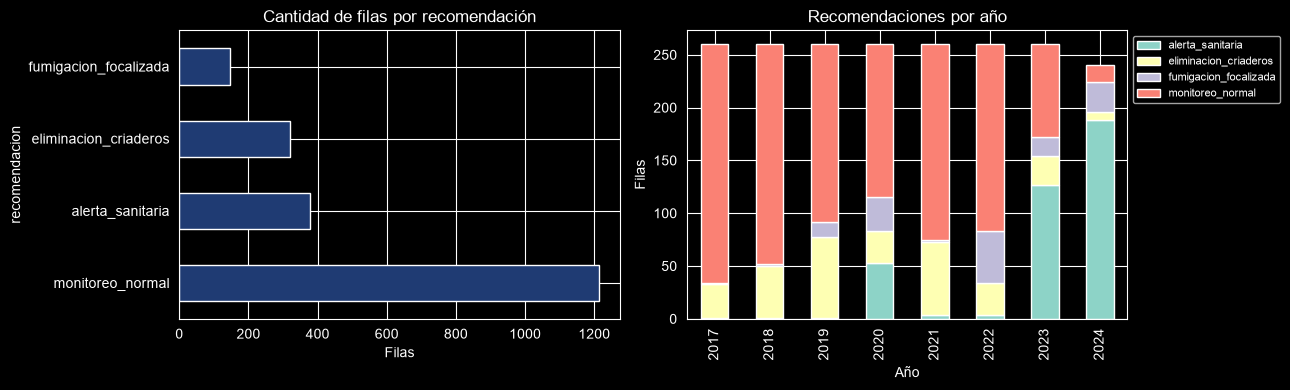

,porcentaje
recomendacion,
monitoreo_normal,58.9
alerta_sanitaria,18.4
eliminacion_criaderos,15.6
fumigacion_focalizada,7.1


In [22]:
conteo_clases = acciones["recomendacion"].value_counts()

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))

conteo_clases.plot(kind="barh", ax=ejes[0], color="#1f3b73")
ejes[0].set_title("Cantidad de filas por recomendación")
ejes[0].set_xlabel("Filas")

pd.crosstab(acciones["anio"], acciones["recomendacion"]).plot(kind="bar", stacked=True, ax=ejes[1])
ejes[1].set_title("Recomendaciones por año")
ejes[1].set_xlabel("Año")
ejes[1].set_ylabel("Filas")
ejes[1].legend(fontsize=8, loc="upper left", bbox_to_anchor=(1, 1))

plt.tight_layout()
plt.show()

(conteo_clases / len(acciones) * 100).round(1).to_frame("porcentaje")

### Interpretación
- El dataset tiene **2,060 filas**: 412 semanas (2017-2024) con 5 escenarios cada una. No tiene valores faltantes.
- Las clases están **desbalanceadas**: monitoreo normal es el 58.9 % de las filas, mientras que fumigación focalizada es solo el 7.1 %.
- Las alertas sanitarias casi no aparecen entre 2017 y 2019 (1 por año) y se concentran en **2023 y 2024** (127 y 188), los años de brote.
- **Decisiones para la ANN:**
  - Usar **class weights** para que el modelo no ignore las clases pequeñas, y reportar precision y recall **por clase**.
  - Dividir train y test **agrupando por semana** (`GroupShuffleSplit` con `groups=fecha_inicio_semana`). Los 5 escenarios de una semana son casi iguales; si se separan al azar por fila, el modelo vería en entrenamiento casi las mismas filas que en prueba.

## 11. Dataset cantonal (mapa de calor)
Este dataset se usa para el mapa de calor de casos por cantón en la app.

In [23]:
cantonal = preparador.cargar_cantonal()
print("Filas:", len(cantonal), "| Años:", sorted(cantonal["anio"].unique()))
print("Cantones por año:")
print(cantonal.groupby("anio")["canton"].count())

Filas: 422 | Años: [np.int64(2013), np.int64(2014), np.int64(2015), np.int64(2016), np.int64(2017), np.int64(2018)]
Cantones por año:
anio
2013    71
2014    71
2015    71
2016    69
2017    71
2018    69
Name: canton, dtype: int64


In [24]:
# Comparación entre la suma de cantones y el total nacional (años en común: 2014-2018)
suma_cantones = cantonal.groupby("anio")["casos_dengue"].sum()
total_nacional = df.groupby("anio")["casos_dengue"].sum()

comparacion = pd.DataFrame({
    "suma_cantones": suma_cantones,
    "total_nacional": total_nacional,
}).dropna()
comparacion["razon"] = (comparacion["suma_cantones"] / comparacion["total_nacional"]).round(2)
comparacion

,suma_cantones,total_nacional,razon
anio,,,
2014,16742.0,11049.0,1.52
2015,25852.0,17485.0,1.48
2016,30700.0,23319.0,1.32
2017,8340.0,5561.0,1.50
2018,4530.0,2735.0,1.66


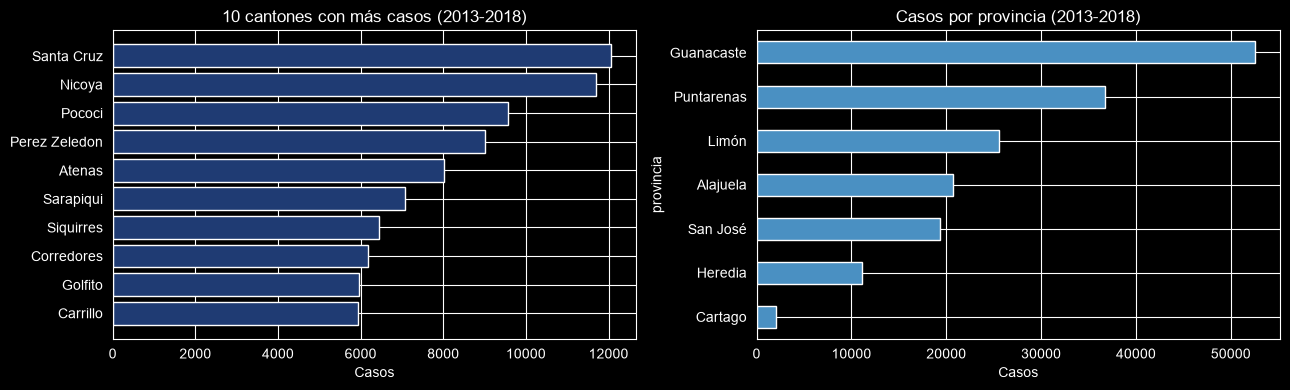

In [25]:
top_cantones = (
    cantonal.groupby(["provincia", "canton"])["casos_dengue"].sum()
    .sort_values(ascending=False).head(10).reset_index()
)
casos_provincia = cantonal.groupby("provincia")["casos_dengue"].sum().sort_values()

fig, ejes = plt.subplots(1, 2, figsize=(13, 4))
ejes[0].barh(top_cantones["canton"][::-1], top_cantones["casos_dengue"][::-1], color="#1f3b73")
ejes[0].set_title("10 cantones con más casos (2013-2018)")
ejes[0].set_xlabel("Casos")

casos_provincia.plot(kind="barh", ax=ejes[1], color="#4a90c2")
ejes[1].set_title("Casos por provincia (2013-2018)")
ejes[1].set_xlabel("Casos")

plt.tight_layout()
plt.show()

### Interpretación
- **Problema de calidad de datos:** la suma de los cantones es entre **1.3 y 1.7 veces mayor** que el total nacional en todos los años en común. Según el LEEME, en 2013 la diferencia es de 81,942 frente a 49,993. Probablemente las fuentes usan definiciones de caso distintas (por ejemplo, casos sospechosos frente a confirmados).
- Algunos años tienen 69 cantones en lugar de 71, así que faltan datos de algunos cantones.
- **Decisión:** en el mapa de calor mostramos los cantones **en proporción** (qué parte de los casos tiene cada cantón) y no como cifras absolutas.
- Los cantones con más casos son de la costa: **Santa Cruz y Nicoya** (Guanacaste), **Pococí** (Limón) y **Pérez Zeledón**. Guanacaste es la provincia con más casos y **Cartago** la que menos, por su altitud y clima frío, donde el mosquito *Aedes aegypti* se reproduce menos.

## 12. Guardar los datos procesados
Guardamos en `data/processed/` la serie nacional con las transformaciones y los rezagos elegidos en este análisis. El notebook del LSTM parte de este archivo.

In [26]:
rezagos_elegidos = {
    "temp_min_c": [6, 8],          # mejor relación entre 6 y 9 semanas (sección 8)
    "log_lluvia": [3, 4],          # mejor relación entre 3 y 4 semanas (sección 8)
    "humedad_rel_pct": [1, 2],     # relación más fuerte con rezagos cortos (sección 8)
}

df_procesado = preparador.agregar_rezagos(df, rezagos_elegidos)
ruta = preparador.guardar_procesado(df_procesado, "dengue_nacional_procesado.csv")

print("Guardado en:", ruta.relative_to(preparador.RAIZ_PROYECTO))
print("Columnas:", list(df_procesado.columns))

Guardado en: data\processed\dengue_nacional_procesado.csv
Columnas: ['fecha_inicio_semana', 'anio', 'semana_epi', 'casos_dengue', 'tasa_100k', 'lluvia_mm', 'temp_max_c', 'temp_min_c', 'humedad_rel_pct', 'mes', 'log_casos', 'log_lluvia', 'lluvia_4sem', 'baseline_estacional', 'temp_min_c_lag6', 'temp_min_c_lag8', 'log_lluvia_lag3', 'log_lluvia_lag4', 'humedad_rel_pct_lag1', 'humedad_rel_pct_lag2']


## 13. Conclusiones
**Sobre los datos**
- La serie nacional tiene 574 semanas continuas y sin faltantes. Tiene años de brote (2016, 2023, 2024) y años tranquilos, con un mismo patrón estacional: los casos suben desde finales de junio, después del inicio de la época lluviosa.
- Hay **subregistro sistemático** en las últimas semanas de cada año (vacaciones), que se compensa en las primeras semanas de enero. Es un problema de registro, no de la enfermedad.
- Los valores atípicos de casos (brotes) y de lluvia (Nate, Eta, Sara) son eventos reales y se mantienen.
- El dataset cantonal no cuadra con el total nacional, por lo que se usa solo en proporciones.

**Para el LSTM (Módulo 2)**
- La entrada más importante son los **casos de las semanas anteriores** (autocorrelación de 0.97).
- Del clima, la **temperatura mínima con 6 a 9 semanas de rezago** es la mejor variable (r = 0.65), seguida de **log(lluvia) con 3 a 4 semanas** (r = 0.37) y la humedad con rezagos cortos.
- La temperatura máxima y la humedad son casi la misma información (r = -0.88).
- Trabajar con **log(casos)**, porque los brotes de 2023-2024 superan el máximo del entrenamiento.
- División temporal: 2014-2022 para entrenar y 2023-2024 para probar. La meta es superar el baseline estacional: **RMSE 630.7 y MAE 447.5** en la prueba.

**Para la ANN (Módulo 3)**
- Las clases están desbalanceadas: usar class weights y reportar precision y recall por clase.
- Separar train y test agrupando por semana, nunca al azar por fila.